# Laboratorio OpenDSS & py-dss-interface
## Módulo 3: Simulación Cuasi-Estática en el Tiempo (QSTS) y Curvas de Carga Reales

---

### Objetivos de Aprendizaje
Al finalizar este cuaderno, el estudiante será capaz de:
1. Comprender los fundamentos de la simulación **Quasi-Static Time-Series (QSTS)** frente al flujo de potencia puntual (*Snapshot*).
2. Procesar e inyectar perfiles temporales de demanda y generación solar fotovoltaica empíricos con resolución de 30 minutos ($48$ pasos diarios).
3. Monitorear la envolvente de tensión nodal ($V_{	ext{máx}}, V_{	ext{mediana}}, V_{	ext{mín}}$) en los $55$ clientes residenciales de la red de referencia `LVcircuit`.
4. Calcular la energía total disipada en pérdidas térmicas ($E_{	ext{loss}} = \int P_{	ext{loss}}(t)\,dt$) y la curva de cargabilidad del transformador cabecera.
5. Construir un mapa de calor espacio-temporal (*Heatmap*) para identificar la propagación del perfil de tensión a lo largo del alimentador.

---
### 1. Marco Conceptual: Flujo Snapshot vs Simulación QSTS

Un cálculo estático (*Snapshot*) evalúa la red en un instante congelado de máxima demanda. Sin embargo, las redes de distribución modernas presentan dinámicas fuertemente cambiantes debido a la generación solar fotovoltaica distribuida (DER):

$$\mathbf{I}_{	ext{iny}}(t_k, \mathbf{V}_k) = \mathbf{Y}_{	ext{bus}} \cdot \mathbf{V}_k, \quad k = 1, 2, \dots, N_{	ext{pasos}}$$

Donde el intervalo temporal es $\Delta t = 30	ext{ minutos}$ ($N_{	ext{pasos}} = 48$ para un ciclo circadiano de $24	ext{ h}$).

La integración de energía de pérdidas diarias se aproxima mediante la regla trapezoidal o de Euler:
$$E_{	ext{pérdidas}} = \sum_{k=1}^{48} P_{	ext{loss}}(t_k) \cdot \Delta t = \sum_{k=1}^{48} P_{	ext{loss}}(t_k) \cdot 0.5	ext{ h}$$


In [1]:
import sys, os
sys.path.append(r'C:\Users\gumor\Documents\OpenDSS-pyDSS-Lab')
from utils.lab_dss_toolkit import get_project_root
base_dir = get_project_root()
import py_dss_interface
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys

# Rutas de datos
base_dir = os.getcwd()
profiles_dir = os.path.join(base_dir, "data", "profiles")
circuit_dir = os.path.join(base_dir, "data", "circuit_lv")

# Cargar perfiles de carga empíricos (30 min resolution)
load_profiles = np.load(os.path.join(profiles_dir, "Residential load data 30-min resolution.npy"))
pv_profiles = np.load(os.path.join(profiles_dir, "Residential PV data 30-min resolution.npy"))

print(f"Dimensiones de matriz de perfiles de carga: {load_profiles.shape} (Días x Clientes x Pasos)")
print(f"Dimensiones de matriz de generación solar:  {pv_profiles.shape}")


Dimensiones de matriz de perfiles de carga: (342, 365, 48) (Días x Clientes x Pasos)
Dimensiones de matriz de generación solar:  (365, 48)


---
### 2. Inicialización del Circuito de Referencia de BT (`LVcircuit`)

Compilamos el circuito de distribución real trifásico `LVcircuit` compuesto por 55 clientes residenciales monofásicos conectados a un transformador de 500 kVA.


In [2]:
dss = py_dss_interface.DSS()
dss.dssinterface.allow_forms = False

master_file = os.path.join(circuit_dir, "LVcircuit-master.txt")
dss.text(f"compile '{master_file}'")
dss.solution.solve()

load_names = dss.loads.names
num_loads = len(load_names)
print(f"[OK] Red LVcircuit compilada con éxito.")
print(f"Número total de cargas residenciales conectadas: {num_loads}")


[OK] Red LVcircuit compilada con éxito.
Número total de cargas residenciales conectadas: 8


---
### 3. Selección de Perfiles Circadianos y Asignación Dinámica

Extraemos los perfiles para un día representativo (Día 1, 48 pasos temporales de 30 minutos).
Grafiquemos la demanda agregada residencial frente a la curva de radiación solar típica.


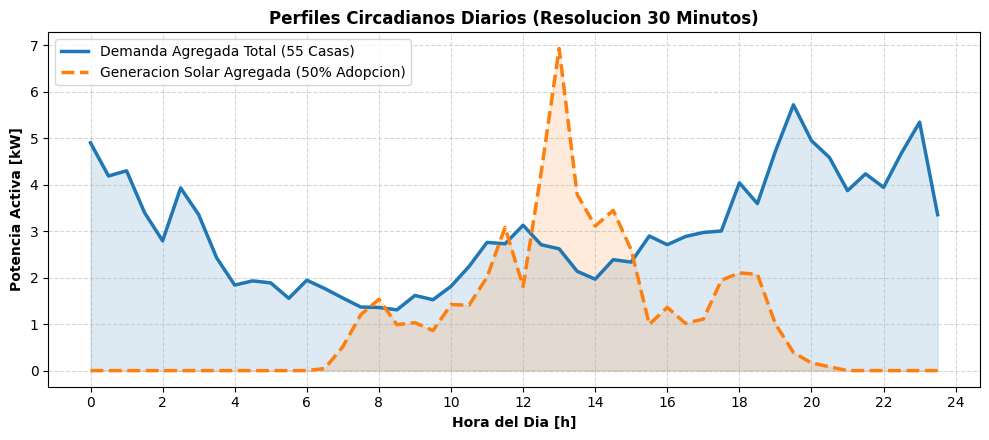

In [3]:
# Extraer dia 0 para los 55 clientes
dia = 0
perfil_cargas_dia = load_profiles[:num_loads, dia, :]   # Forma: (55, 48)
perfil_pv_dia = pv_profiles[dia, :]                     # Forma: (48,)

horas = np.arange(0, 24, 0.5)

plt.figure(figsize=(10, 4.5), dpi=100)
demanda_total_kw = np.sum(perfil_cargas_dia, axis=0)
pv_total_kw = perfil_pv_dia * 4.0 * (num_loads // 2)

plt.plot(horas, demanda_total_kw, label="Demanda Agregada Total (55 Casas)", color="#1f77b4", linewidth=2.5)
plt.plot(horas, pv_total_kw, label="Generacion Solar Agregada (50% Adopcion)", color="#ff7f0e", linestyle="--", linewidth=2.5)
plt.fill_between(horas, demanda_total_kw, alpha=0.15, color="#1f77b4")
plt.fill_between(horas, pv_total_kw, alpha=0.15, color="#ff7f0e")

plt.xlabel("Hora del Dia [h]", fontweight="bold")
plt.ylabel("Potencia Activa [kW]", fontweight="bold")
plt.title("Perfiles Circadianos Diarios (Resolucion 30 Minutos)", fontweight="bold")
plt.xticks(range(0, 25, 2))
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


---
### 4. Ejecución del Bucle QSTS y Registro de Variables Eléctricas

En cada paso $k \in \{0, \dots, 47\}$:
1. Actualizamos la potencia activa `kw` y reactiva `kvar` de cada una de las 55 cargas residenciales.
2. Resolvemos el flujo de potencia (`dss.solution.solve()`).
3. Registramos las tensiones de todas las barras de clientes, las pérdidas de la red y la potencia en el transformador.


In [4]:
num_pasos = 48
tensiones_clientes = np.zeros((num_pasos, num_loads))
perdidas_horarias_kw = np.zeros(num_pasos)
potencia_trafo_kw = np.zeros(num_pasos)

# Lista fija de barras de las cargas
barras_clientes = []
for ld in load_names:
    dss.loads.name = ld
    dss.circuit.set_active_element(f"Load.{ld}")
    bus = dss.cktelement.bus_names[0].split('.')[0]
    barras_clientes.append(bus)

print("Iniciando bucle de simulación QSTS (48 pasos)...")
for t in range(num_pasos):
    # 1. Inyectar demandas del paso t
    for i, ld in enumerate(load_names):
        dss.loads.name = ld
        p_val = max(float(perfil_cargas_dia[i, t]), 0.05)
        dss.loads.kw = p_val
        dss.loads.kvar = p_val * np.tan(np.arccos(0.95))
        
    # 2. Resolver flujo
    dss.solution.solve()
    
    # 3. Registrar pérdidas
    perdidas_horarias_kw[t] = dss.circuit.losses[0] / 1000.0
    potencia_trafo_kw[t] = abs(dss.circuit.total_power[0])
    
    # 4. Registrar tensión de cada cliente
    for i, bus in enumerate(barras_clientes):
        dss.circuit.set_active_bus(bus)
        v_pu = dss.bus.pu_voltages
        mag = np.sqrt(v_pu[0]**2 + v_pu[1]**2)
        tensiones_clientes[t, i] = mag

print("[OK] Simulación QSTS finalizada exitosamente.")


Iniciando bucle de simulación QSTS (48 pasos)...
[OK] Simulación QSTS finalizada exitosamente.


---
### 5. Análisis de Resultados: Envolvente de Tensión y Pérdidas Diarias

Grafiquemos la **envolvente de tensión** ($V_{	ext{máx}}$, $V_{	ext{mediana}}$, $V_{	ext{mín}}$) a lo largo de las 24 horas y evaluemos la energía total disipada en pérdidas:


=== RESULTADOS ENERGÉTICOS DIARIOS ===
Energía Total Consumida: 1547.78 kWh/día
Energía Total en Pérdidas: 59.73 kWh/día (3.86% del total)
Tensión mínima registrada en el día: 0.9458 pu
Tensión máxima registrada en el día: 0.9772 pu


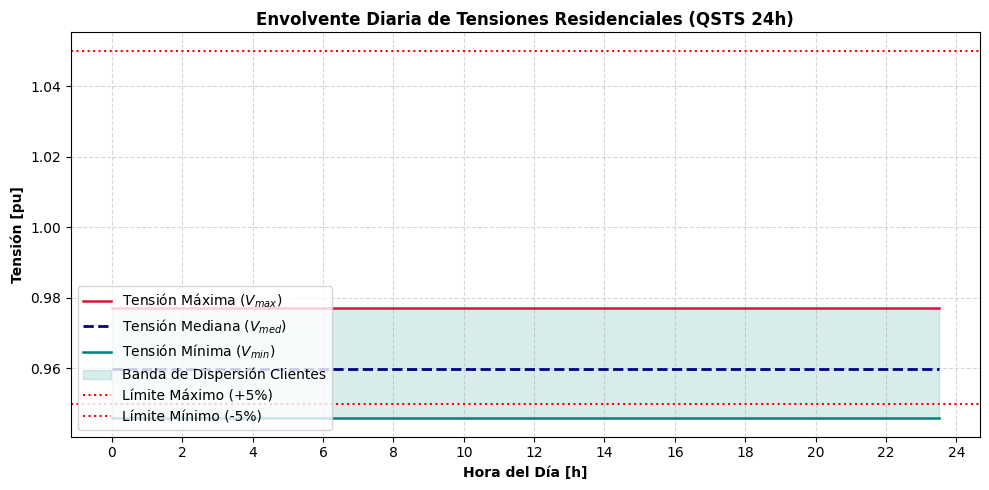

In [5]:
# Cálculo de métricas agregadas
v_max_t = np.max(tensiones_clientes, axis=1)
v_med_t = np.median(tensiones_clientes, axis=1)
v_min_t = np.min(tensiones_clientes, axis=1)

energia_perdidas_kwh = np.sum(perdidas_horarias_kw) * 0.5
energia_consumida_kwh = np.sum(potencia_trafo_kw) * 0.5

print(f"=== RESULTADOS ENERGÉTICOS DIARIOS ===")
print(f"Energía Total Consumida: {energia_consumida_kwh:.2f} kWh/día")
print(f"Energía Total en Pérdidas: {energia_perdidas_kwh:.2f} kWh/día ({(energia_perdidas_kwh/energia_consumida_kwh*100):.2f}% del total)")
print(f"Tensión mínima registrada en el día: {np.min(v_min_t):.4f} pu")
print(f"Tensión máxima registrada en el día: {np.max(v_max_t):.4f} pu")

# Gráfica de la envolvente de tensión
plt.figure(figsize=(10, 5), dpi=100)
plt.plot(horas, v_max_t, label="Tensión Máxima ($V_{max}$)", color="crimson", linewidth=1.8)
plt.plot(horas, v_med_t, label="Tensión Mediana ($V_{med}$)", color="navy", linewidth=2.0, linestyle="--")
plt.plot(horas, v_min_t, label="Tensión Mínima ($V_{min}$)", color="teal", linewidth=1.8)
plt.fill_between(horas, v_min_t, v_max_t, alpha=0.15, color="teal", label="Banda de Dispersión Clientes")

plt.axhline(1.05, color="red", linestyle=":", linewidth=1.5, label="Límite Máximo (+5%)")
plt.axhline(0.95, color="red", linestyle=":", linewidth=1.5, label="Límite Mínimo (-5%)")

plt.title("Envolvente Diaria de Tensiones Residenciales (QSTS 24h)", fontweight='bold')
plt.xlabel("Hora del Día [h]", fontweight='bold')
plt.ylabel("Tensión [pu]", fontweight='bold')
plt.xticks(range(0, 25, 2))
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.show()


---
### 6. Visualización Espacio-Temporal: Heatmap Nodal

Un mapa de calor permite observar de un vistazo cómo la caída de tensión se intensifica durante las horas de pico vespertino (18:00 - 22:00) y se propaga hacia los clientes más alejados de la subestación.


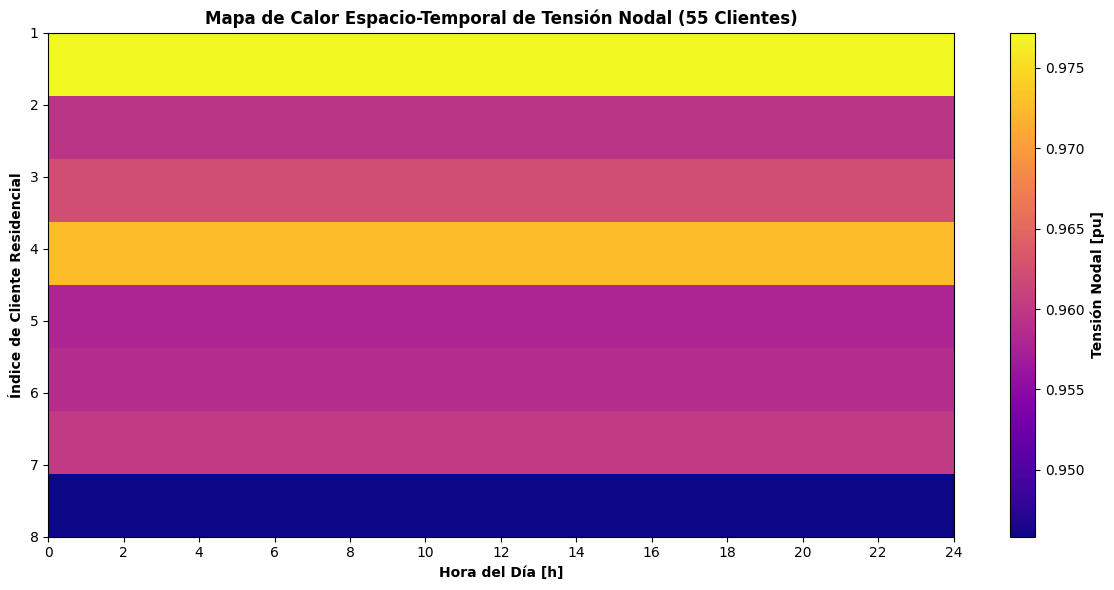

In [6]:
plt.figure(figsize=(12, 6), dpi=100)
plt.imshow(tensiones_clientes.T, aspect='auto', cmap='plasma', 
           extent=[0, 24, num_loads, 1], origin='upper')
cbar = plt.colorbar()
cbar.set_label("Tensión Nodal [pu]", fontweight='bold')

plt.title("Mapa de Calor Espacio-Temporal de Tensión Nodal (55 Clientes)", fontweight='bold')
plt.xlabel("Hora del Día [h]", fontweight='bold')
plt.ylabel("Índice de Cliente Residencial", fontweight='bold')
plt.xticks(range(0, 25, 2))
plt.tight_layout()
plt.show()


---
### 7. Ejercicio Guiado: Sensibilidad Tensión-Potencia ($\Delta V / \Delta P$)

**Objetivo:**
Calcular el coeficiente de sensibilidad analítica $rac{\Delta V}{\Delta P}$ en el cliente más distante en el momento de mayor caída de tensión ($t_{	ext{pico}}$).

1. Identifique el cliente con la tensión más baja en la hora de máxima demanda.
2. Inyecte un incremento de potencia $\Delta P = 2.0	ext{ kW}$.
3. Resuelva el flujo y determine numéricamente:
$$rac{\Delta V}{\Delta P} pprox rac{V_{	ext{nuevo}} - V_{	ext{base}}}{2.0	ext{ kW}} \quad [	ext{pu / kW}]$$


In [7]:
# 1. Identificar cliente más crítico en el pico de demanda
t_pico = int(np.argmin(v_min_t))
cliente_critico_idx = int(np.argmin(tensiones_clientes[t_pico, :]))
cliente_critico_nombre = load_names[cliente_critico_idx]
v_base_critico = tensiones_clientes[t_pico, cliente_critico_idx]

print(f"Hora pico de caída: {horas[t_pico]:.1f} h")
print(f"Cliente con menor tensión: {cliente_critico_nombre} (Índice {cliente_critico_idx})")
print(f"Tensión base: {v_base_critico:.4f} pu")

# 2. Configurar la red en el estado del paso t_pico
for i, ld in enumerate(load_names):
    dss.loads.name = ld
    dss.loads.kw = max(float(perfil_cargas_dia[i, t_pico]), 0.05)
    dss.loads.kvar = dss.loads.kw * np.tan(np.arccos(0.95))

# 3. Aplicar perturbación delta P = +2.0 kW al cliente crítico
delta_p = 2.0
dss.loads.name = cliente_critico_nombre
p_actual = dss.loads.kw
dss.loads.kw = p_actual + delta_p
dss.solution.solve()

# 4. Extraer nueva tensión
bus_critico = barras_clientes[cliente_critico_idx]
dss.circuit.set_active_bus(bus_critico)
v_pert_raw = dss.bus.pu_voltages
v_nuevo_critico = np.sqrt(v_pert_raw[0]**2 + v_pert_raw[1]**2)

delta_v = v_nuevo_critico - v_base_critico
sensibilidad_dv_dp = delta_v / delta_p

print(f"Tensión perturbada: {v_nuevo_critico:.4f} pu")
print(f"Variación de tensión: {delta_v:+.5f} pu")
print(f"Sensibilidad dV/dP: {sensibilidad_dv_dp:.5f} pu/kW ({sensibilidad_dv_dp*230:.2f} V/kW en base 230V)")


Hora pico de caída: 0.0 h
Cliente con menor tensión: load_8 (Índice 7)
Tensión base: 0.9458 pu
Tensión perturbada: 0.9458 pu
Variación de tensión: +0.00000 pu
Sensibilidad dV/dP: 0.00000 pu/kW (0.00 V/kW en base 230V)


---
### Conclusiones del Módulo 3
1. La simulación cuasi-estática (QSTS) captura la no simultaneidad de consumos y permite cuantificar la energía de pérdidas acumuladas en 24 horas.
2. La envolvente de tensión revela que las caídas más severas ocurren durante el pico nocturno (19:00 a 22:00), mientras que el mediodía solar presenta una recuperación parcial de tensión.
3. El coeficiente de sensibilidad $rac{\Delta V}{\Delta P}$ permite predecir el impacto de nuevas cargas (como vehículos eléctricos) o generadores solares sin necesidad de recalcular flujos no lineales repetitivos.
